## サイン波の予測

In [29]:
import torch
from torch import nn, optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py
from tqdm import tqdm

device = torch.device("xpu" if torch.xpu.is_available() else "cpu")
print(device)

xpu


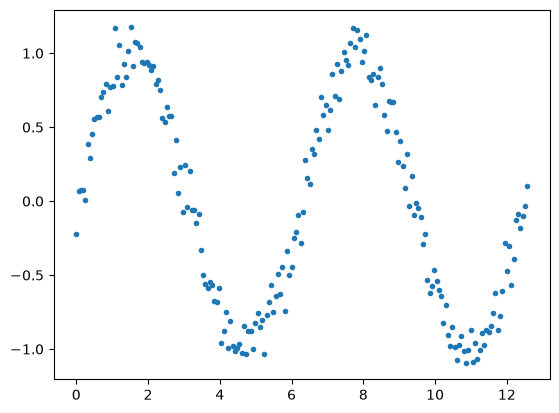

In [14]:
def generate_train_data():


    # 訓練データ
    x = np.linspace(0, 4*np.pi, 200)
    rng = np.random.default_rng(seed = 2025)
    sin_x = np.sin(x) + rng.normal(0, 0.1, len(x))

    fig,ax = plt.subplots()

    ax.plot(x,sin_x,
            lw = 0,
            marker = ".",)

    return {"x": x, "y": sin_x}
TrainingData = generate_train_data()
del generate_train_data

In [34]:
# ハイパーパラメータ
hyper_parameter = {}
hyper_parameter["n_time"] = 40 # 10個の時系列を1セット
hyper_parameter["n_sample"] = len(TrainingData["x"]) - hyper_parameter["n_time"] # 40
hyper_parameter["batch_size"] = 32
hyper_parameter["length"] = {
    "train": 0.8,
    "validation": 0.1
}
print(json.dumps(hyper_parameter, indent = 4))

{
    "n_time": 40,
    "n_sample": 160,
    "batch_size": 32,
    "length": {
        "train": 0.8,
        "validation": 0.1
    }
}


In [35]:
# 前処理
def process_data(data, parameter):
    ## 空の配列を準備
    input_data = np.zeros((parameter["n_sample"], parameter["n_time"], 1))
    correct_data = np.zeros((parameter["n_sample"], 1))

    ## 配列にTrainDataを格納
    for i in tqdm(range(parameter["n_sample"])):
        input_data[i] = data["y"][i:i+parameter["n_time"]].reshape(-1,1)
        correct_data[i] = [data["y"][i+parameter["n_time"]]]
    input_data = torch.FloatTensor(input_data)
    correct_data = torch.FloatTensor(correct_data)

    ## バッチデータの準備
    full_dataset = TensorDataset(input_data, correct_data)
    n_total = len(full_dataset)
    n_train = int(hyper_parameter["length"]["train"]*n_total)
    n_val = int(hyper_parameter["length"]["validation"]*n_total)
    n_test = n_total-n_train-n_val

    ## データを分類
    dataset = random_split(
        full_dataset,
        [n_train, n_val, n_test],
        generator = torch.Generator().manual_seed(42)
    )
    loader = {}
    for k, d in zip(["train", "val", "test"], dataset):
        loader[k] = DataLoader(
            d,
            batch_size = parameter["batch_size"],
            shuffle = True if (k=="train") else False
        )

    return dataset, loader
dataset, loader = process_data(data = TrainingData, parameter = hyper_parameter)

100%|██████████| 160/160 [00:00<00:00, 466357.64it/s]


In [47]:
# モデルの定義
class RNN(nn.Module):
    def __init__(self): # コンストラクタを定義
        super(RNN, self).__init__()
        self.rnn = nn.RNN(1, 64, batch_first=True) # RNNのモジュール（入力1、隠れ層64）
        self.fc = nn.Linear(64, 1) # 全結合層（入力64、出力1）
    def forward(self, x):
        batch_size = x.size(0) # 入力の行数をバッチサイズに設定
        x = x.to(device) # 処理をGPUに移行
        x_rnn, hidden = self.rnn(x, None) # ?
        x = self.fc(x_rnn[:, -1, :])
        return x

model = RNN().to(device)
criterion = nn.MSELoss() # 平均二乗誤差
optimizer = optim.SGD(model.parameters(), lr=0.01) # 確率的勾配降下法

In [48]:
record_loss_train = []
record_loss_val = []
len_epoch = 1000

for i in tqdm(range(len_epoch)):
    model.train() # 訓練モード
    loss_train = 0
    for j, (x, t) in enumerate(loader["train"]):
        loss = criterion(model(x), t.to(device))
        loss_train += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss_train /= j+1
    record_loss_train.append(loss_train)

    model.eval()
    loss_val = 0
    with torch.no_grad():
        for j, (x, t) in enumerate(loader["val"]):
            loss = criterion(model(x), t.to(device))
            loss_val += loss.item()
        loss_val /= j+1
        record_loss_val.append(loss_val)


100%|██████████| 1000/1000 [01:02<00:00, 15.95it/s]


In [60]:
with torch.no_grad():
    for j, (x,t) in enumerate(loader["train"]):
        print(j)

0
1
2
3


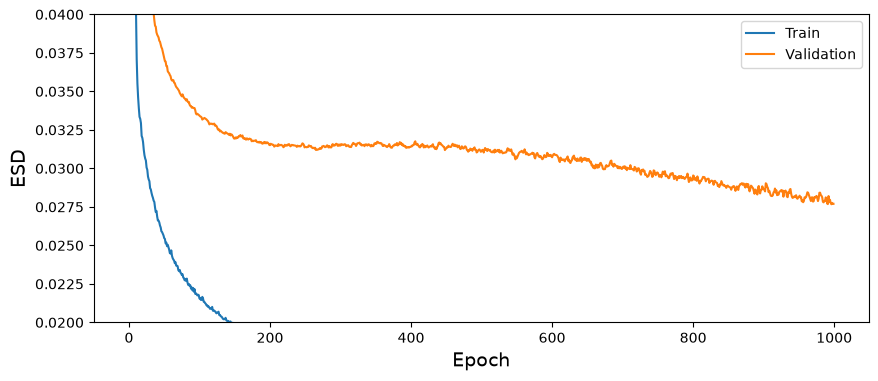

In [57]:
fig, ax = plt.subplots()
fig.set_size_inches(10,4)

ax.plot(
    range(len_epoch),
    record_loss_train, 
    label = "Train"
)
ax.plot(
    range(len_epoch),
    record_loss_val,
    label = "Validation"
)
ax.set_ylim(0,0.1)
ax.set_ylim(0.02,0.04)
ax.legend()
ax.set_xlabel("Epoch", fontsize = 14)
ax.set_ylabel("ESD", fontsize = 14)
plt.show()

In [ ]:
record_loss_train = []
len_epoch = 201

for i in range(len_epoch):
    model.train() # 訓練モード
    loss_train = 0
    for j, (x, t) in enumerate(loader["train"]):
        loss = criterion(model(x), t.to(device))
        loss_train += loss.item()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    loss_train /= j+1
    record_loss_train.append(loss_train)

    if i%20 == 0:
        print("Epoch: {}, Loss_Train: {}".format(i, loss_train))
        predicted = list(dataset[0][0].__array__().reshape(-1))
        model.eval()
        with torch.no_grad():
            for i in range(hyper_parameter["n_sample"]):
                x = torch.tensor(predicted[-hyper_parameter["n_time"]:])
                x = x.reshape(1, hyper_parameter["n_time"], 1)
                predicted.append(model(x)[0].item())

        fig, ax = plt.subplots()
        ax.plot(
            TrainingData["x"],
            TrainingData["y"],
            lw = 0,
            marker = ".",
            label = "Correct"
        )
        ax.plot(
            TrainingData["x"],
            predicted,
            label = "Model"
        )
        plt.show()
        plt.close()

初めの誤差： 36.18 %
最終誤差　： 1.74  %


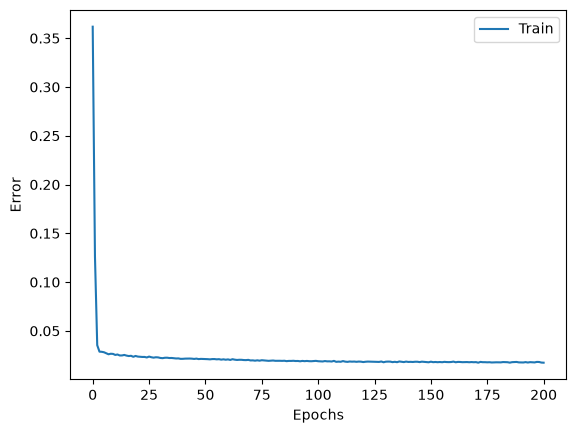

In [19]:
'''精度の確認'''
print('初めの誤差：', round(record_loss_train[0]*100,2), '%')
print('最終誤差　：', round(record_loss_train[-1]*100,2), ' %')
plt.plot(range(len(record_loss_train)), record_loss_train, label='Train')
plt.legend()
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()